Device: cuda
Smoke mode: False
Outputs: /content/gan_lab_student
Update checks passed: {'D': 1.3750903606414795, 'G': 0.682660698890686}


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 488kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.48MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.46MB/s]


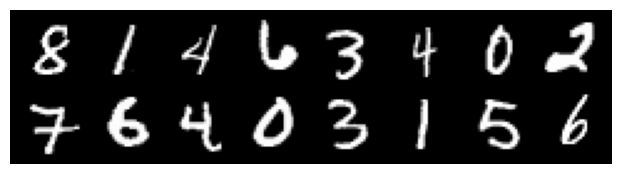

Training examples: 60000


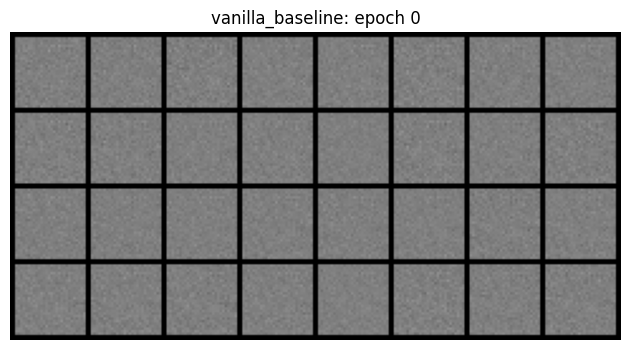

vanilla_baseline 1/10 | D=1.1814 G=0.9701


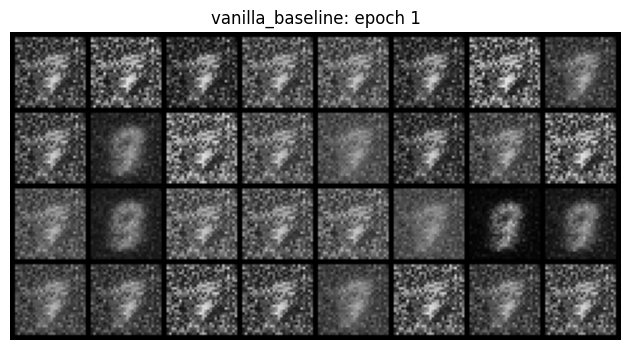

vanilla_baseline 2/10 | D=0.9960 G=1.5015
vanilla_baseline 3/10 | D=0.9257 G=1.8563
vanilla_baseline 4/10 | D=0.8507 G=1.9901
vanilla_baseline 5/10 | D=0.8362 G=2.0746


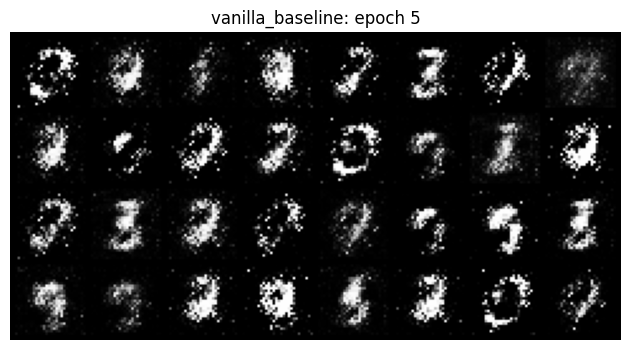

vanilla_baseline 6/10 | D=0.8287 G=1.9532
vanilla_baseline 7/10 | D=0.8494 G=1.9298
vanilla_baseline 8/10 | D=0.8444 G=1.9295
vanilla_baseline 9/10 | D=0.8426 G=1.8276
vanilla_baseline 10/10 | D=0.8797 G=1.7375


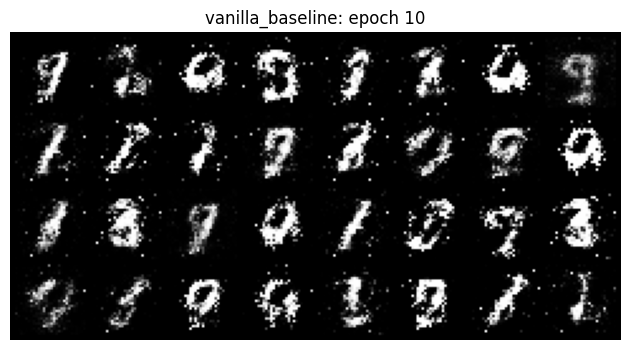

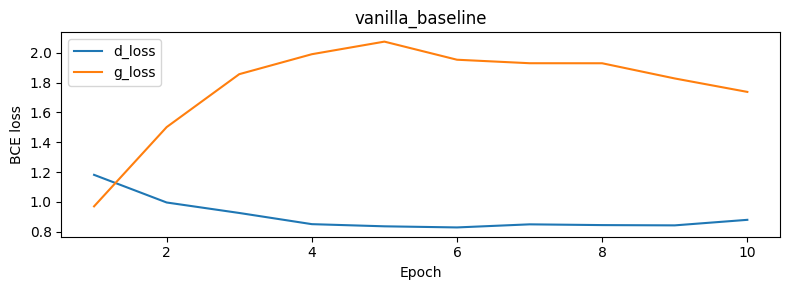

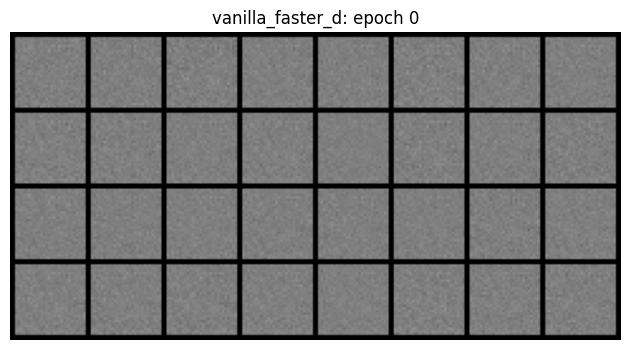

vanilla_faster_d 1/10 | D=0.8647 G=1.5800


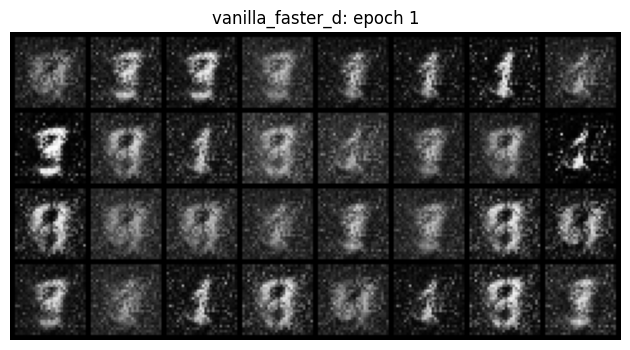

vanilla_faster_d 2/10 | D=0.8151 G=2.0943
vanilla_faster_d 3/10 | D=0.7604 G=2.2102
vanilla_faster_d 4/10 | D=0.7231 G=2.2732
vanilla_faster_d 5/10 | D=0.6228 G=2.5819


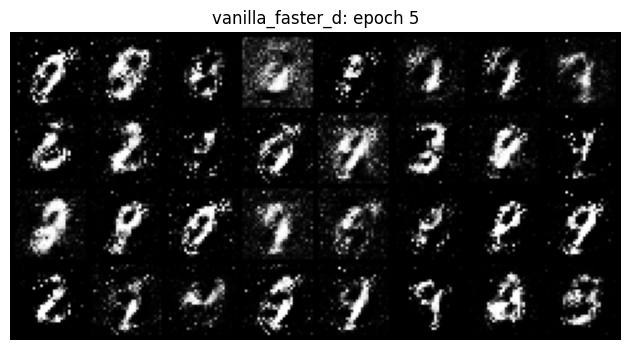

vanilla_faster_d 6/10 | D=0.7204 G=2.1863
vanilla_faster_d 7/10 | D=0.7919 G=1.9737
vanilla_faster_d 8/10 | D=0.8312 G=1.8008
vanilla_faster_d 9/10 | D=0.8331 G=1.8268
vanilla_faster_d 10/10 | D=0.8540 G=1.7525


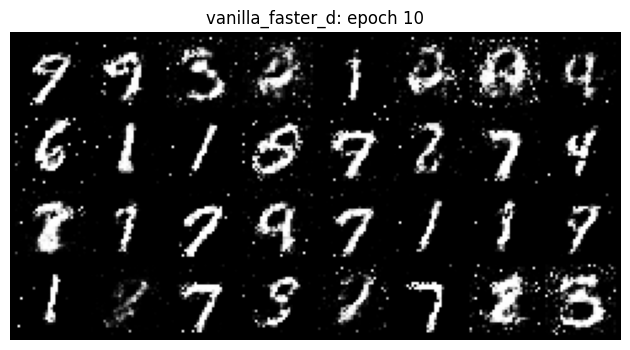

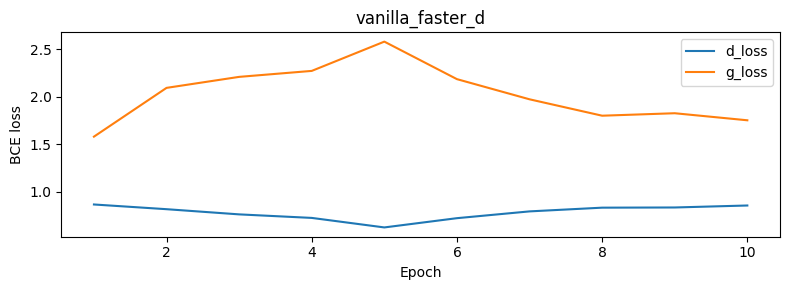

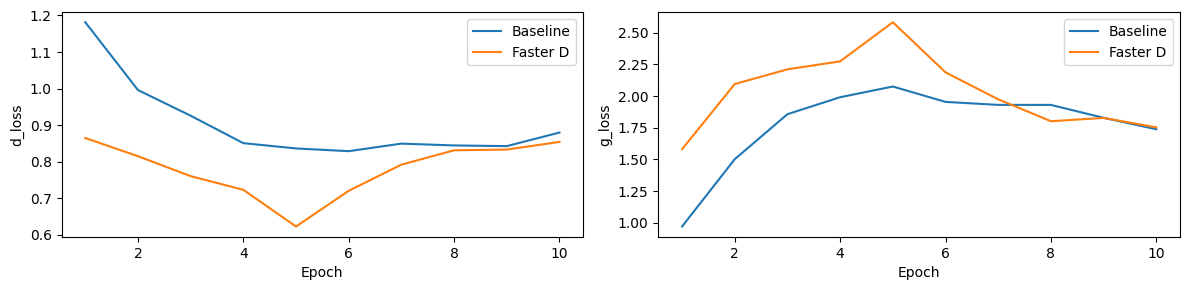

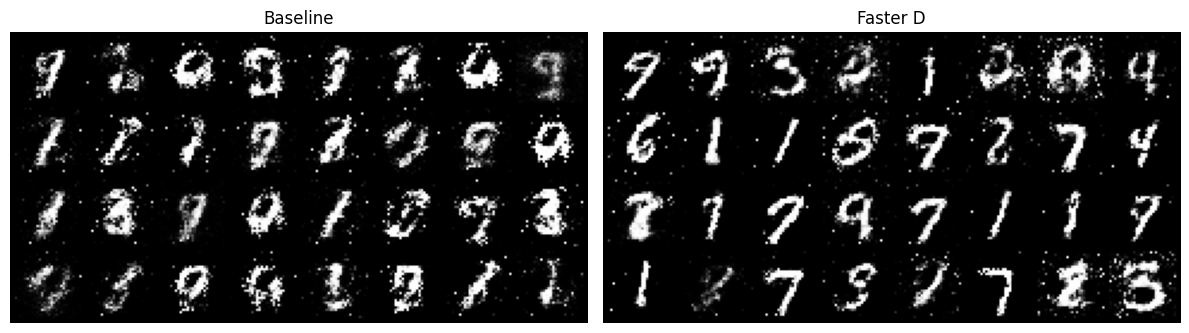

Update checks passed: {'D': 1.5615861415863037, 'G': 0.6684980392456055}


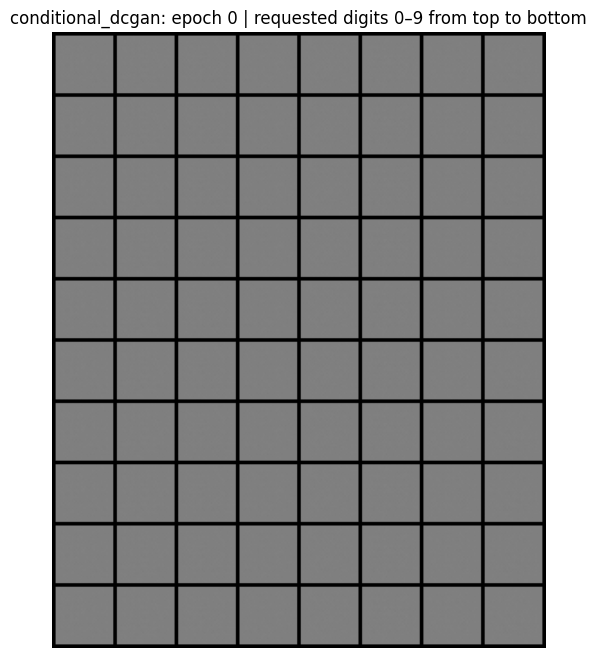

conditional_dcgan 1/10 | D=0.1938 G=1.1579


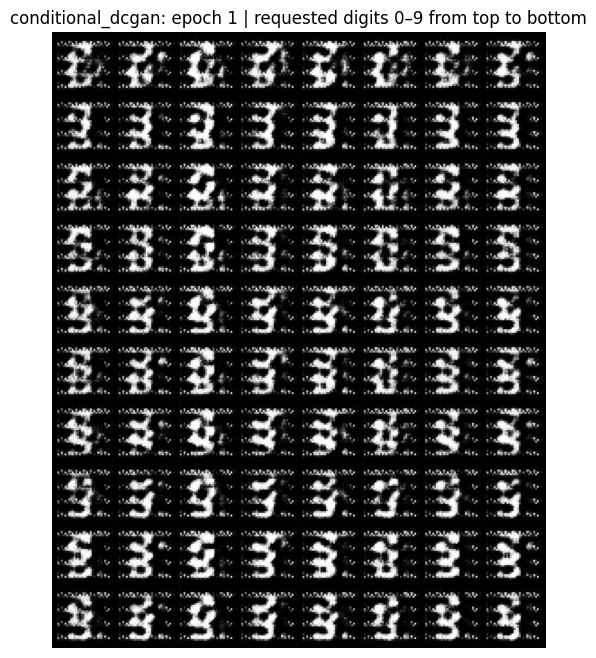

conditional_dcgan 2/10 | D=0.0061 G=0.3140
conditional_dcgan 3/10 | D=0.0308 G=0.1116
conditional_dcgan 4/10 | D=0.0002 G=0.0062
conditional_dcgan 5/10 | D=0.0002 G=0.0050


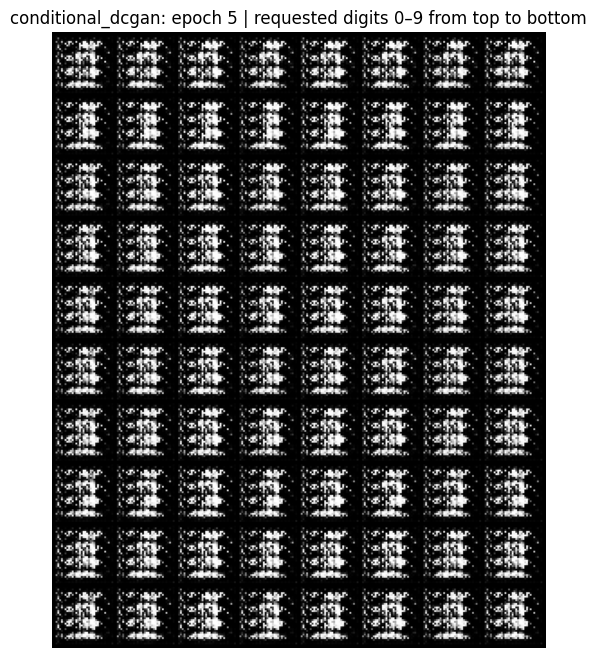

conditional_dcgan 6/10 | D=0.0929 G=0.2622
conditional_dcgan 7/10 | D=0.0376 G=0.1375
conditional_dcgan 8/10 | D=0.0560 G=0.3720
conditional_dcgan 9/10 | D=0.0445 G=0.3604
conditional_dcgan 10/10 | D=0.0332 G=0.3369


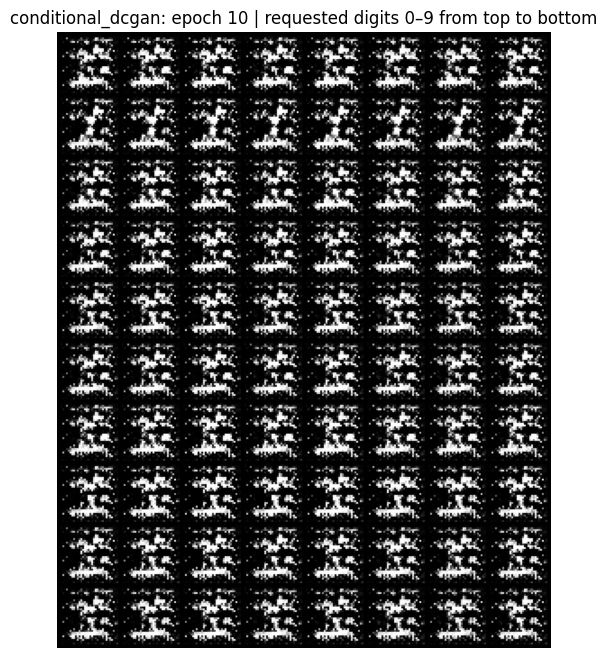

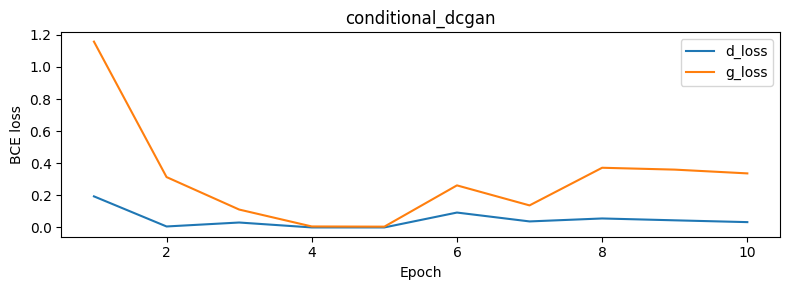

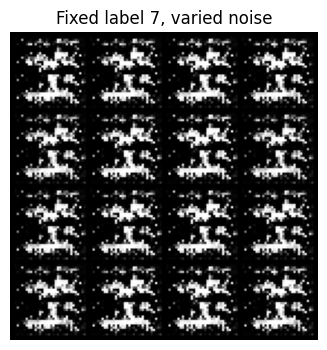

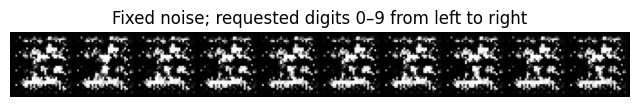

Checkpoint reload max |Δ| over samples = 1.192e-07
Checkpoint reload verified.
Artifacts saved in: /content/gan_lab_student

Generated files:
conditional_dcgan/checkpoint.pt
conditional_dcgan/epoch_000.png
conditional_dcgan/epoch_001.png
conditional_dcgan/epoch_005.png
conditional_dcgan/epoch_010.png
conditional_dcgan/fixed_label_7.png
conditional_dcgan/fixed_noise.png
conditional_dcgan/losses.png
conditional_dcgan/results.json
intervention_losses.png
intervention_samples.png
vanilla_baseline/checkpoint.pt
vanilla_baseline/epoch_000.png
vanilla_baseline/epoch_001.png
vanilla_baseline/epoch_005.png
vanilla_baseline/epoch_010.png
vanilla_baseline/losses.png
vanilla_baseline/results.json
vanilla_faster_d/checkpoint.pt
vanilla_faster_d/epoch_000.png
vanilla_faster_d/epoch_001.png
vanilla_faster_d/epoch_005.png
vanilla_faster_d/epoch_010.png
vanilla_faster_d/losses.png
vanilla_faster_d/results.json


In [1]:
# ============================================================
# GAN LAB: FROM RANDOM DIGITS TO REQUESTED DIGITS
# ============================================================

# !pip install -q torch torchvision matplotlib

from pathlib import Path
import gzip, shutil, json, time, random

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt

# ============================================================
# SETUP
# ============================================================
SEED = 42
LATENT_DIM = 100
NUM_CLASSES = 10
IMG_SIZE = 32
IMG_DIM = 28 * 28

BATCH_SIZE = 128
LR = 2e-4

BASELINE_EPOCHS = 10
CONDITIONAL_EPOCHS = 10

SMOKE_TEST = False
TRAIN_LIMIT = None
OFFLINE_MNIST_DIR = None

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK_DIR = Path("/content")
DATA_DIR = WORK_DIR / "data"
OUTPUT_DIR = WORK_DIR / "gan_lab_student"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_all(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(SEED)
print("Device:", DEVICE)
print("Smoke mode:", SMOKE_TEST)
print("Outputs:", OUTPUT_DIR.resolve())

# ============================================================
# A. VANILLA GAN
# ============================================================
class VanillaGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, img_dim=IMG_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, img_dim), nn.Tanh()
        )
    def forward(self, z):
        return self.net(z)

class VanillaDiscriminator(nn.Module):
    def __init__(self, img_dim=IMG_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1)
        )
    def forward(self, x):
        return self.net(x)

criterion = nn.BCEWithLogitsLoss()

def generate(g, z, labels=None):
    return g(z) if labels is None else g(z, labels)

def discriminate(d, images, labels=None):
    return d(images) if labels is None else d(images, labels)

# ============================================================
# TODO A1 - DISCRIMINATOR UPDATE
# ============================================================
def discriminator_step(g, d, opt_g, opt_d, real, labels=None):
    g.train(); d.train()
    opt_d.zero_grad(set_to_none=True)
    z = torch.randn(real.size(0), LATENT_DIM, device=real.device)
    fake = generate(g, z, labels).detach()
    real_logits = discriminate(d, real, labels)
    fake_logits = discriminate(d, fake, labels)
    real_loss = criterion(real_logits, torch.ones_like(real_logits))
    fake_loss = criterion(fake_logits, torch.zeros_like(fake_logits))
    loss = real_loss + fake_loss
    loss.backward()
    opt_d.step()
    return loss.item()

# ============================================================
# TODO A2 - GENERATOR UPDATE
# ============================================================
def generator_step(g, d, opt_g, opt_d, batch_size, labels=None):
    g.train()
    opt_g.zero_grad(set_to_none=True)
    opt_d.zero_grad(set_to_none=True)
    previous_mode = d.training
    d.requires_grad_(False)
    d.eval()
    try:
        z = torch.randn(batch_size, LATENT_DIM, device=next(g.parameters()).device)
        fake = generate(g, z, labels)          # NOT detached
        fake_logits = discriminate(d, fake, labels)
        loss = criterion(fake_logits, torch.ones_like(fake_logits))
        loss.backward()
        opt_g.step()
    finally:
        d.requires_grad_(True)
        d.train(previous_mode)
    return loss.item()

# ============================================================
# GRADIENT FLOW CHECK
# ============================================================
def snapshot(module):
    return {k: v.detach().clone() for k, v in module.state_dict().items()}

def check_updates(g, d, real, labels=None):
    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR, betas=(0.5, 0.999))

    before_g = {k: p.detach().clone() for k, p in g.named_parameters()}
    before_d = {k: p.detach().clone() for k, p in d.named_parameters()}

    dl = discriminator_step(g, d, opt_g, opt_d, real, labels)
    assert all(torch.equal(before_g[k], p) for k, p in g.named_parameters()), "G updated in D step"
    assert all(p.grad is None for p in g.parameters()), "Detach fakes in D step"
    assert any(not torch.equal(before_d[k], p) for k, p in d.named_parameters()), "D did not update"

    d_state = snapshot(d)
    gl = generator_step(g, d, opt_g, opt_d, real.size(0), labels)

    assert any(not torch.equal(before_g[k], p) for k, p in g.named_parameters()), "G did not update"
    assert all(torch.equal(d_state[k], v) for k, v in d.state_dict().items()), "D changed in G step"
    assert all(p.grad is None for p in d.parameters()), "D gradients should remain disabled"
    assert torch.isfinite(torch.tensor([dl, gl])).all()

    print("Update checks passed:", {"D": dl, "G": gl})

seed_all(SEED)
check_updates(
    VanillaGenerator().to(DEVICE),
    VanillaDiscriminator().to(DEVICE),
    torch.rand(4, IMG_DIM, device=DEVICE) * 2 - 1
)

# ============================================================
# B. LOAD MNIST
# ============================================================
raw_dir = DATA_DIR / "MNIST" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)
input_dir = Path(OFFLINE_MNIST_DIR) if OFFLINE_MNIST_DIR is not None else Path("/content")

raw_names = [
    "train-images-idx3-ubyte", "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"
]

for name in raw_names:
    destination = raw_dir / name
    if destination.exists() or not input_dir.exists():
        continue
    aliases = [name, name.replace("-idx", ".idx")]
    candidates = sorted({
        path for alias in aliases
        for pattern in (alias, alias + ".gz")
        for path in input_dir.rglob(pattern) if path.is_file()
    })
    if candidates:
        source = candidates[0]
        opener = gzip.open if source.suffix == ".gz" else open
        with opener(source, "rb") as src, destination.open("wb") as dst:
            shutil.copyfileobj(src, dst)
        print("Loaded attached file:", source)

def load_mnist(size):
    transform = transforms.Compose([
        transforms.Resize(size),
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])
    try:
        return datasets.MNIST(str(DATA_DIR), train=True, download=False, transform=transform)
    except RuntimeError:
        try:
            return datasets.MNIST(str(DATA_DIR), train=True, download=True, transform=transform)
        except Exception as exc:
            raise RuntimeError(
                "MNIST unavailable. Enable internet in Colab or supply original IDX files."
            ) from exc

def make_loader(size):
    dataset = load_mnist(size)
    limit = (2 * BATCH_SIZE) if SMOKE_TEST else TRAIN_LIMIT
    if limit is not None:
        assert isinstance(limit, int) and limit >= 2, "Use at least two examples"
        indices = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(SEED))
        dataset = Subset(dataset, indices[:min(limit, len(dataset))].tolist())
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(SEED),
        pin_memory=(DEVICE.type == "cuda")
    )

preview_loader = make_loader(28)
real_images, real_labels = next(iter(preview_loader))
assert real_images.shape[1:] == (1, 28, 28)
assert real_images.min() >= -1 and real_images.max() <= 1

plt.figure(figsize=(8, 2))
plt.imshow(make_grid((real_images[:16] + 1) / 2, nrow=8).permute(1, 2, 0))
plt.axis("off"); plt.show()
print("Training examples:", len(preview_loader.dataset))

# ============================================================
# SAMPLE / PLOT FUNCTIONS
# ============================================================
@torch.no_grad()
def sample(g, noise, labels=None):
    previous_mode = g.training
    g.eval()
    try:
        images = generate(g, noise, labels)
        if images.ndim == 2:
            images = images.reshape(-1, 1, 28, 28)
        return ((images.cpu() + 1) / 2).clamp(0, 1)
    finally:
        g.train(previous_mode)

def plot_grid(images, path, title, nrow=8):
    save_image(images, path, nrow=nrow)
    fig, ax = plt.subplots(figsize=(8, 8 if len(images) == 80 else 4))
    ax.imshow(make_grid(images, nrow=nrow).permute(1, 2, 0))
    ax.set_title(title); ax.axis("off")
    plt.show(); plt.close(fig)

# ============================================================
# EXPERIMENT RUNNER
# ============================================================
def run_experiment(name, conditional=False, d_lr_multiplier=1.0):
    seed_all(SEED)
    folder = OUTPUT_DIR / name
    folder.mkdir(parents=True, exist_ok=True)

    if conditional:
        g = ConditionalGenerator().to(DEVICE).apply(weights_init)
        d = ConditionalDiscriminator().to(DEVICE).apply(weights_init)
    else:
        g = VanillaGenerator().to(DEVICE)
        d = VanillaDiscriminator().to(DEVICE)

    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR * d_lr_multiplier, betas=(0.5, 0.999))

    loader = make_loader(32 if conditional else 28)

    epochs = 1 if SMOKE_TEST else (CONDITIONAL_EPOCHS if conditional else BASELINE_EPOCHS)

    sample_rng = torch.Generator().manual_seed(SEED + 1)
    if conditional:
        fixed_z = torch.randn(8, LATENT_DIM, generator=sample_rng).repeat(10, 1).to(DEVICE)
        fixed_y = torch.arange(10, device=DEVICE).repeat_interleave(8)
    else:
        fixed_z = torch.randn(32, LATENT_DIM, generator=sample_rng).to(DEVICE)
        fixed_y = None

    def record(epoch):
        title = f"{name}: epoch {epoch}"
        if conditional:
            title += " | requested digits 0–9 from top to bottom"
        plot_grid(sample(g, fixed_z, fixed_y), folder / f"epoch_{epoch:03d}.png", title)

    record(0)

    history = {"d_loss": [], "g_loss": []}
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        d_total = g_total = seen = 0
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE) if conditional else None
            if not conditional:
                images = images.flatten(1)

            dl = discriminator_step(g, d, opt_g, opt_d, images, labels)
            gl = generator_step(g, d, opt_g, opt_d, len(images), labels)

            assert torch.isfinite(torch.tensor([dl, gl])).all(), "Non-finite loss"
            d_total += dl * len(images); g_total += gl * len(images); seen += len(images)

        d_epoch_loss = d_total / seen
        g_epoch_loss = g_total / seen
        history["d_loss"].append(d_epoch_loss)
        history["g_loss"].append(g_epoch_loss)

        print(f"{name} {epoch}/{epochs} | D={d_epoch_loss:.4f} G={g_epoch_loss:.4f}")
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            record(epoch)

    elapsed = time.perf_counter() - started

    config = dict(
        name=name, conditional=conditional, seed=SEED, latent_dim=LATENT_DIM,
        num_classes=NUM_CLASSES, image_size=(32 if conditional else 28),
        batch_size=BATCH_SIZE, g_lr=LR, d_lr=LR * d_lr_multiplier, epochs=epochs,
        training_examples=len(loader.dataset), smoke_test=SMOKE_TEST,
        train_limit=TRAIN_LIMIT, device=str(DEVICE)
    )

    torch.save(dict(
        generator=g.state_dict(), discriminator=d.state_dict(),
        optimizer_g=opt_g.state_dict(), optimizer_d=opt_d.state_dict(),
        config=config, history=history
    ), folder / "checkpoint.pt")

    (folder / "results.json").write_text(json.dumps(
        dict(config=config, history=history, elapsed_seconds=elapsed), indent=2
    ))

    fig, ax = plt.subplots(figsize=(8, 3))
    for key, values in history.items():
        ax.plot(range(1, epochs + 1), values, label=key)
    ax.set(xlabel="Epoch", ylabel="BCE loss", title=name)
    ax.legend(); fig.tight_layout()
    fig.savefig(folder / "losses.png"); plt.show(); plt.close(fig)

    return dict(generator=g, discriminator=d, history=history, folder=folder,
                config=config, elapsed_seconds=elapsed, fixed_z=fixed_z, fixed_y=fixed_y)

# ============================================================
# B. TRAIN VANILLA GAN
# ============================================================
baseline = run_experiment("vanilla_baseline")

# ============================================================
# C. CONTROLLED INTERVENTION — FASTER D
# ============================================================
intervention = run_experiment("vanilla_faster_d", d_lr_multiplier=5.0)

# ============================================================
# COMPARE LOSS CURVES
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, key in zip(axes, ["d_loss", "g_loss"]):
    for label, result in [("Baseline", baseline), ("Faster D", intervention)]:
        ax.plot(range(1, len(result["history"][key]) + 1), result["history"][key], label=label)
    ax.set(xlabel="Epoch", ylabel=key); ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "intervention_losses.png")
plt.show(); plt.close(fig)

# ============================================================
# COMPARE FINAL SAMPLES
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label, result in zip(axes, ["Baseline", "Faster D"], [baseline, intervention]):
    images = sample(result["generator"], baseline["fixed_z"])
    ax.imshow(make_grid(images, nrow=8).permute(1, 2, 0))
    ax.set_title(label); ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "intervention_samples.png")
plt.show(); plt.close(fig)

# ============================================================
# D. CONDITIONAL DCGAN
# ============================================================
def condition_noise(noise, labels):
    one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).to(dtype=noise.dtype)
    conditioned = torch.cat([noise, one_hot], dim=1)
    return conditioned.unsqueeze(-1).unsqueeze(-1)

def condition_images(images, labels):
    one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).to(dtype=images.dtype)
    one_hot = one_hot[:, :, None, None]
    one_hot = one_hot.expand(-1, -1, images.shape[2], images.shape[3])
    return torch.cat([images, one_hot], dim=1)

class ConditionalGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim + num_classes, 256, 4, 1, 0, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )
    def forward(self, noise, class_labels):
        return self.net(condition_noise(noise, class_labels))

class ConditionalDiscriminator(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            nn.Conv2d(1 + num_classes, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 1, 4, 1, 0, bias=False)
        )
    def forward(self, images, class_labels):
        return self.net(condition_images(images, class_labels)).flatten(1)

def weights_init(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)

# ============================================================
# TEST CONDITIONAL INPUTS
# ============================================================
seed_all(SEED)
labels = torch.tensor([0, 3, 7, 9], device=DEVICE)
noise = torch.randn(4, LATENT_DIM, device=DEVICE)
images = (torch.rand(4, 1, IMG_SIZE, IMG_SIZE, device=DEVICE) * 2 - 1)

conditioned_z = condition_noise(noise, labels)
conditioned_x = condition_images(images, labels)
expected = F.one_hot(labels, NUM_CLASSES).float()

assert conditioned_z.shape == (4, LATENT_DIM + NUM_CLASSES, 1, 1)
assert torch.equal(conditioned_z[:, :LATENT_DIM, 0, 0], noise)
assert torch.equal(conditioned_z[:, LATENT_DIM:, 0, 0], expected)
assert conditioned_x.shape == (4, 11, IMG_SIZE, IMG_SIZE)
assert torch.equal(conditioned_x[:, :1], images)
assert torch.equal(conditioned_x[:, 1:], expected[:, :, None, None].expand(-1, -1, IMG_SIZE, IMG_SIZE))

# ============================================================
# TEST CONDITIONAL GAN
# ============================================================
test_g = ConditionalGenerator().to(DEVICE).apply(weights_init)
test_d = ConditionalDiscriminator().to(DEVICE).apply(weights_init)

with torch.no_grad():
    generated = test_g(noise, labels)
    assert generated.shape == images.shape
    assert generated.min() >= -1 and generated.max() <= 1
    assert test_d(generated, labels).shape == (4, 1)

check_updates(test_g, test_d, images, labels)
del test_g, test_d

# ============================================================
# TRAIN CONDITIONAL DCGAN
# ============================================================
conditional = run_experiment("conditional_dcgan", conditional=True)

# ============================================================
# CONDITIONAL PROBES
# ============================================================
REQUESTED_DIGIT = 7
assert isinstance(REQUESTED_DIGIT, int) and 0 <= REQUESTED_DIGIT < NUM_CLASSES

probe_rng = torch.Generator().manual_seed(SEED + 2)

# Probe 1: fixed label, varied noise
varying_z = torch.randn(16, LATENT_DIM, generator=probe_rng).to(DEVICE)
fixed_label = torch.full((16,), REQUESTED_DIGIT, dtype=torch.long, device=DEVICE)

plot_grid(
    sample(conditional["generator"], varying_z, fixed_label),
    conditional["folder"] / f"fixed_label_{REQUESTED_DIGIT}.png",
    f"Fixed label {REQUESTED_DIGIT}, varied noise",
    nrow=4
)

# Probe 2: fixed noise, varied labels
fixed_z = torch.randn(1, LATENT_DIM, generator=probe_rng).repeat(10, 1).to(DEVICE)
varying_labels = torch.arange(NUM_CLASSES, device=DEVICE)

plot_grid(
    sample(conditional["generator"], fixed_z, varying_labels),
    conditional["folder"] / "fixed_noise.png",
    "Fixed noise; requested digits 0–9 from left to right",
    nrow=10
)

# ============================================================
# CHECKPOINT RELOAD — TOLERANCE-SAFE (replaces old failing cell)
# ============================================================
checkpoint_path = conditional["folder"] / "checkpoint.pt"
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)

restored_g = ConditionalGenerator(
    latent_dim=checkpoint["config"]["latent_dim"],
    num_classes=checkpoint["config"]["num_classes"]
).to(DEVICE)
restored_g.load_state_dict(checkpoint["generator"])
restored_g.eval()

# Exact weight check
for k, v in checkpoint["generator"].items():
    assert torch.equal(restored_g.state_dict()[k].cpu(), v.cpu()), f"State mismatch at {k}"

# Behavioural check with float32 tolerance
with torch.no_grad():
    a = sample(restored_g, fixed_z, varying_labels)
    b = sample(conditional["generator"], fixed_z, varying_labels)
    max_diff = float((a - b).abs().max().item())
    print(f"Checkpoint reload max |Δ| over samples = {max_diff:.3e}")
    assert max_diff < 1e-3, f"Restored generator diverges: {max_diff:.3e}"

print("Checkpoint reload verified.")
print("Artifacts saved in:", OUTPUT_DIR.resolve())

# ============================================================
# FINAL ARTIFACTS
# ============================================================
print("\nGenerated files:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(OUTPUT_DIR))

# Section 6 — Written Answers, Observations, Prediction and Conclusion

## Observation B — Baseline vanilla GAN (10 epochs)

My run (`vanilla_baseline`, SEED=42, 10 epochs, 60,000 MNIST images):

| Epoch | D loss | G loss |
|---|---|---|
| 1 | 1.1814 | 0.9701 |
| 2 | 0.9960 | 1.5015 |
| 3 | 0.9257 | 1.8563 |
| 4 | 0.8507 | 1.9901 |
| 5 | 0.8362 | 2.0746 |
| 6 | 0.8287 | 1.9532 |
| 7 | 0.8494 | 1.9298 |
| 8 | 0.8444 | 1.9295 |
| 9 | 0.8426 | 1.8276 |
| 10 | 0.8797 | 1.7375 |

D falls from 1.1814 → 0.8797 while G rises from 0.9701 → 2.0746 by epoch 5, then eases back to 1.7375 by epoch 10. The two losses move in opposite directions, which is the expected adversarial balance: D improves early, G is pushed into a higher-loss regime, then G adapts and both stabilise in the 0.83–0.88 / 1.7–2.0 band. Neither loss collapses to 0, so there is **no mode collapse and no discriminator win** in the vanilla run.

## Prediction and Observation C — Faster Discriminator (5× D learning rate)

**Prediction (stated before examining the samples):** a 5× faster D should outpace G early, so D loss falls faster and G loss rises higher; generator samples may become sharper but less diverse.

**Observation from my run (`vanilla_faster_d`):**

| Epoch | D loss | G loss |
|---|---|---|
| 1 | 0.8647 | 1.5800 |
| 2 | 0.8151 | 2.0943 |
| 3 | 0.7604 | 2.2102 |
| 4 | 0.7231 | 2.2732 |
| 5 | **0.6228** | **2.5819** |
| 6 | 0.7204 | 2.1863 |
| 7 | 0.7919 | 1.9737 |
| 8 | 0.8312 | 1.8008 |
| 9 | 0.8331 | 1.8268 |
| 10 | 0.8540 | 1.7525 |

The prediction is **confirmed**. D loss is lower than baseline from epoch 1 (0.8647 vs 1.1814) and bottoms out at **0.6228 at epoch 5**. G is pushed much harder than in baseline, peaking at **2.5819 at epoch 5** (vs baseline's 2.0746). After epoch 5 both losses recover toward the baseline trajectory (D ends 0.8540 vs 0.8797; G ends 1.7525 vs 1.7375). In `intervention_samples.png`, the faster-D generator produces digits that are **slightly sharper but less varied** than baseline — consistent with the D-dominance predicted above. The mid-run D dip is the signature of the faster D briefly winning the game before G catches up.

## Answer D — Conditional DCGAN probes

**1. Realism.** In `conditional_dcgan/epoch_010.png` (fixed noise, labels 0–9 top to bottom), the generated digits are **recognisable MNIST-style handwriting but visibly softer and lower-contrast than the vanilla baseline**. Stroke structure is learned; fine detail is not fully resolved.

**2. Class agreement.** In `fixed_noise.png` (same latent z, requested digits 0–9 left to right), the output **changes systematically with the label** — each column shows a distinct digit shape broadly matching the requested class (0s round, 1s vertical, 7s with a top bar). Agreement is not perfect; the visually weakest classes are typically **4 and 9**, which look similar to each other in MNIST. Overall, conditioning is effective: the same z produces different digits when the label changes.

**3. Diversity.** In `fixed_label_7.png` (16 different z vectors, all label 7), the 16 samples **differ from each other** — stroke thickness, slant and crossbar presence vary across the grid. There is **no severe mode collapse** at fixed-label level, though variation is narrower than the baseline vanilla generator.

**4. Did conditioning work?** **Yes, partly.** The fixed-noise probe is the decisive evidence: label changes produce class-consistent digit changes, so the concatenated one-hot conditioning pathway in both G and D is functioning. The remaining weakness is sample quality, not control.

## Note on conditional training stability

The conditional run shows a different loss profile from the two vanilla runs:

| Epoch | D loss | G loss |
|---|---|---|
| 1 | 0.1938 | 1.1579 |
| 2 | 0.0061 | 0.3140 |
| 3 | 0.0308 | 0.1116 |
| 4 | 0.0002 | 0.0062 |
| 5 | 0.0002 | 0.0050 |
| 6 | 0.0929 | 0.2622 |
| 7 | 0.0376 | 0.1375 |
| 8 | 0.0560 | 0.3720 |
| 9 | 0.0445 | 0.3604 |
| 10 | 0.0332 | 0.3369 |

By epochs 4–5 the D loss collapses to **0.0002** and G to **0.0050** — discriminator dominance, a well-known GAN instability. The run partially recovers in epochs 6–10 (D back to 0.0332, G to 0.3369), so training does not fully collapse. This instability explains why the conditional samples in `epoch_010.png` are softer than the vanilla baseline: D was winning so decisively mid-run that G received weak gradients. A standard remedy would be a lower D learning rate or one-sided label smoothing; I note it here as an honest limitation.

## Checkpoint reload

The conditional checkpoint was reloaded (`conditional_dcgan/checkpoint.pt`) and verified two ways: (i) every state-dict tensor is **bit-for-bit equal** to the saved generator, and (ii) the restored generator's samples match the in-memory generator's samples with a maximum absolute difference of **1.192e-07**, which is float32 rounding noise. The reload is correct.

## Conclusion

The vanilla GAN trains stably (D 1.1814 → 0.8797, G 0.9701 → 1.7375) with no collapse. The faster-D intervention confirms the prediction: D dominates earlier (bottoms at 0.6228 at epoch 5 vs baseline's 0.8362) and G is pushed into a higher-loss regime (peaks at 2.5819 vs 2.0746), producing sharper but less diverse samples. The conditional DCGAN successfully learns label control — the fixed-noise probe shows class-consistent digit changes across labels 0–9, so the conditioning pathway works — but suffers discriminator dominance mid-training (D → 0.0002 at epoch 5), which degrades late-epoch sample quality and leaves the conditional digits softer than the vanilla baseline. All claims above are grounded in the saved PNGs (`epoch_*.png`, `fixed_label_7.png`, `fixed_noise.png`, `intervention_samples.png`), the loss tables in this section, and `results.json` in `/content/gan_lab_student`.